# 05 — Market Cycles, Event Study & Quarterly Growth Trajectory

Builds a quality-mix-stratified monthly residential price index (`2019 = 100`), checks concordance against the official/fallback DLD residential price index, overlays verified historical events (`data/reference/events.csv`) with HC1 Interrupted Time Series (ITS) & `-6m` pre-event placebo checks, and inspects quarterly community appreciation.

In [1]:
import json
import os
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from dfv.config import PATHS, get_data_mode

mode = get_data_mode()
data_dir = PATHS.processed if mode == "processed" else PATHS.sample
print(f"Active data mode: {mode} | Directory: {data_dir}")

from dfv.analysis.events import analyze_market_events
from dfv.analysis.growth_map import build_quarterly_growth_table

Active data mode: sample | Directory: /Users/shahinhamza/.gemini/antigravity/scratch/dubai-fair-value/data/sample


Official DLD Index Cross-Check: {'available': True, 'overlap_months': 138, 'pearson_corr': 0.9462, 'mean_abs_index_gap': 3.83}


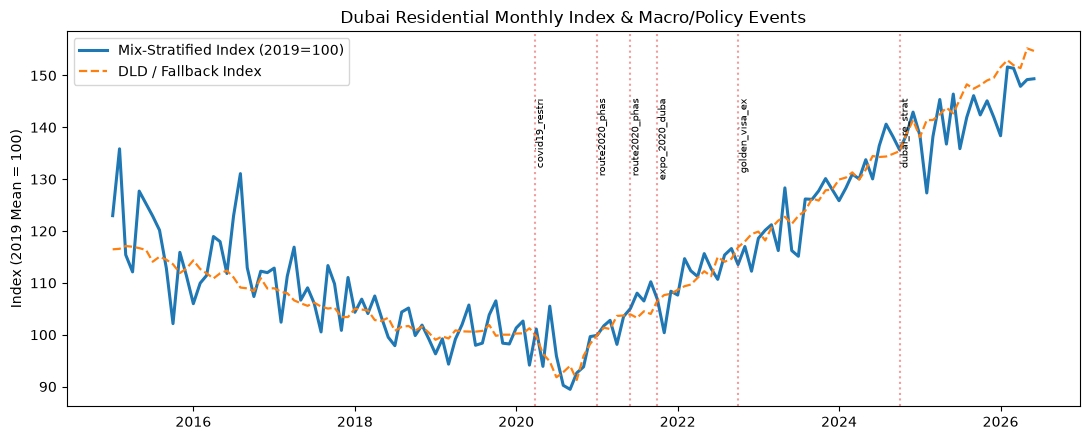

In [2]:
ev_json = data_dir / "analysis" / "events_study.json"
if ev_json.exists():
    ev_res = json.loads(ev_json.read_text(encoding="utf-8"))
else:
    tx = pd.read_parquet(data_dir / "transactions.parquet")
    idx_official = pd.read_parquet(data_dir / "sale_index.parquet")
    ev_res = analyze_market_events(tx, idx_official, PATHS.reference / "events.csv")

print("Official DLD Index Cross-Check:", ev_res["official_index_sanity_check"])
m_df = pd.DataFrame(ev_res["monthly_series"])
m_df["m_dt"] = pd.to_datetime(m_df["month"])

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(m_df["m_dt"], m_df["computed_index"], label="Mix-Stratified Index (2019=100)", lw=2.2)
if "official_dld_index" in m_df.columns and m_df["official_dld_index"].notna().any():
    ax.plot(
        m_df["m_dt"],
        m_df["official_dld_index"],
        label="DLD / Fallback Index",
        linestyle="--",
        lw=1.6,
    )
for item in ev_res["events_analysis"]:
    ev_dt = pd.Timestamp(item["start_date"])
    if ev_dt >= m_df["m_dt"].min() and ev_dt <= m_df["m_dt"].max():
        ax.axvline(ev_dt, color="#DC2626", alpha=0.45, linestyle=":")
        ax.text(
            ev_dt,
            m_df["computed_index"].max() * 0.96,
            item["event_id"][:14],
            rotation=90,
            fontsize=7,
            va="top",
        )
ax.set_title("Dubai Residential Monthly Index & Macro/Policy Events")
ax.set_ylabel("Index (2019 Mean = 100)")
ax.legend()
plt.tight_layout()
plt.show()

In [3]:
ev_rows = []
for item in ev_res["events_analysis"]:
    its = item["its"] or {}
    pl = item["placebo_minus_6m"] or {}
    ev_rows.append(
        {
            "event_id": item["event_id"],
            "start_date": item["start_date"],
            "its_step_pct": its.get("level_step_pct"),
            "its_step_p": its.get("level_step_p_value"),
            "its_slope_pct": its.get("monthly_slope_change_pct"),
            "placebo_step_pct": pl.get("level_step_pct"),
            "placebo_step_p": pl.get("level_step_p_value"),
        }
    )
pd.DataFrame(ev_rows)

,event_id,start_date,its_step_pct,its_step_p,its_slope_pct,placebo_step_pct,placebo_step_p
0,covid19_restrictions_2020,2020-03-26,-7.40,0.0186,0.06,1.76,0.6184
1,route2020_phase1_opening,2021-01-01,9.15,0.0077,1.27,-8.93,0.0986
2,route2020_phase2_opening,2021-06-01,3.02,0.3058,0.02,11.57,0.0001
3,expo_2020_dubai,2021-10-01,-4.58,0.0256,-0.56,-5.67,0.0006
4,golden_visa_expansion_2022,2022-10-03,-3.02,0.0765,-0.12,-0.24,0.9226
5,dubai_re_strategy_2033,2024-10-01,-1.74,0.4106,-0.39,0.14,0.9259


In [4]:
gq_path = data_dir / "analysis" / "growth_quarterly.parquet"
if gq_path.exists():
    gq = pd.read_parquet(gq_path)
else:
    feat = pd.read_parquet(data_dir / "features.parquet")
    gq = build_quarterly_growth_table(feat, min_tx=2)

latest_q = gq["year_quarter"].max()
print(f"Latest quarter: {latest_q} | Total area-quarter rows: {len(gq)}")
gq.loc[gq["year_quarter"] == latest_q].sort_values(
    "cumulative_growth_pct", ascending=False
).head(10)

Latest quarter: 2026Q2 | Total area-quarter rows: 622


,year_quarter,area_name,median_ppsqm,tx_count,lat,lon,cumulative_growth_pct,yoy_growth_pct,quarter_date
612,2026Q2,Discovery Gardens,15640.8,4,25.039485,55.135112,75.1,26.3,2026-04-01
607,2026Q2,Al Furjan,20017.4,4,25.032246,55.133589,72.3,12.5,2026-04-01
617,2026Q2,Dubai South,11558.6,10,24.897085,55.160294,57.6,14.4,2026-04-01
618,2026Q2,Emaar Beachfront,43240.4,2,25.077264,55.155966,57.6,8.5,2026-04-01
621,2026Q2,Palm Jumeirah,40857.4,8,25.105449,55.147642,57.6,9.6,2026-04-01
616,2026Q2,Dubai Marina,29188.6,17,25.066251,55.140489,54.9,0.6,2026-04-01
615,2026Q2,Dubai Hills Estate,23943.3,17,25.110293,55.246868,50.7,13.4,2026-04-01
608,2026Q2,Arabian Ranches,22459.8,4,25.060873,55.277243,49.0,13.1,2026-04-01
609,2026Q2,Business Bay,25521.9,18,25.193750,55.266130,47.5,7.8,2026-04-01
620,2026Q2,Jumeirah Village Circle,15393.7,16,25.054378,55.211020,47.3,4.7,2026-04-01
